In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import re
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Original dataset shape:", df.shape)

print("First 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nColumn names:")
print(df.columns.tolist())

print("\nStatistical summary:")
display(df.describe(include="all"))

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

clean_df = df.dropna(subset=["Review Text"]).copy()

clean_df["Clean_Review"] = (
    clean_df["Review Text"]
    .astype(str)
    .str.lower()
    .str.strip()
)

print("Original rows:", len(df))
print("Rows after cleaning:", len(clean_df))
print("Removed rows:", len(df) - len(clean_df))

positive_words = [
    "excellent", "good", "love", "beautiful",
    "perfect", "comfortable", "happy", "great",
    "soft", "nice", "recommend", "wonderful",
    "amazing", "flattering", "gorgeous", "pretty",
    "favorite", "pleased", "fantastic", "stylish",
    "lovely", "fabulous", "best"
]

negative_words = [
    "bad", "poor", "disappointed", "uncomfortable",
    "damaged", "awful", "terrible", "defective",
    "horrible", "waste", "unhappy", "broken",
    "cheap", "ugly", "worst", "return",
    "disappointing", "unflattering", "itchy",
    "unfortunately", "wrong", "issue", "problem"
]

negation_words = ["not", "no", "never", "hardly"]

def analyze_sentiment(review):

    words = re.findall(r"\b\w+\b", str(review).lower())

    positive_count = 0
    negative_count = 0

    for i, word in enumerate(words):

        previous_words = words[max(0, i-3):i]

        has_negation = any(
            negation in previous_words
            for negation in negation_words
        )

        if word in positive_words:

            if has_negation:
                negative_count += 1
            else:
                positive_count += 1

        elif word in negative_words:

            if has_negation:
                positive_count += 1
            else:
                negative_count += 1

    if positive_count > negative_count:
        return "Positive"

    elif negative_count > positive_count:
        return "Negative"

    else:
        return "Neutral"

        test_reviews = [
    "This dress is good",
    "This dress is not good",
    "This dress is bad",
    "This dress is not bad"
]

for review in test_reviews:
    print(review, ":", analyze_sentiment(review))


    clean_df["Sentiment"] = clean_df["Clean_Review"].apply(
    analyze_sentiment
)

print("Sentiment analysis completed!")

display(
    clean_df[["Review Text", "Clean_Review", "Sentiment"]].head(10)
)


sentiment_counts = clean_df["Sentiment"].value_counts()

sentiment_percentage = (
    clean_df["Sentiment"].value_counts(normalize=True) * 100
)

sentiment_summary = pd.DataFrame({
    "Review_Count": sentiment_counts,
    "Percentage": sentiment_percentage.round(2)
})

display(sentiment_summary)

Saving Data set.csv to Data set (2).csv
Dataset loaded successfully!
Original dataset shape: (23486, 11)
First 5 rows:


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Unnamed: 0               23486 non-null  int64 
 1   Clothing ID              23486 non-null  int64 
 2   Age                      23486 non-null  int64 
 3   Title                    19676 non-null  object
 4   Review Text              22641 non-null  object
 5   Rating                   23486 non-null  int64 
 6   Recommended IND          23486 non-null  int64 
 7   Positive Feedback Count  23486 non-null  int64 
 8   Division Name            23472 non-null  object
 9   Department Name          23472 non-null  object
 10  Class Name               23472 non-null  object
dtypes: int64(6), object(5)
memory usage: 2.0+ MB

Column names:
['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count'

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
count,23486.000000,23486.000000,23486.000000,19676,22641,23486.000000,23486.000000,23486.000000,23472,23472,23472
unique,NaN,NaN,NaN,13993,22634,NaN,NaN,NaN,3,6,20
top,NaN,NaN,NaN,Love it!,Perfect fit and i've gotten so many compliment...,NaN,NaN,NaN,General,Tops,Dresses
freq,NaN,NaN,NaN,136,3,NaN,NaN,NaN,13850,10468,6319
mean,11742.500000,918.118709,43.198544,NaN,NaN,4.196032,0.822362,2.535936,NaN,NaN,NaN
std,6779.968547,203.298980,12.279544,NaN,NaN,1.110031,0.382216,5.702202,NaN,NaN,NaN
min,0.000000,0.000000,18.000000,NaN,NaN,1.000000,0.000000,0.000000,NaN,NaN,NaN
25%,5871.250000,861.000000,34.000000,NaN,NaN,4.000000,1.000000,0.000000,NaN,NaN,NaN
50%,11742.500000,936.000000,41.000000,NaN,NaN,5.000000,1.000000,1.000000,NaN,NaN,NaN
75%,17613.750000,1078.000000,52.000000,NaN,NaN,5.000000,1.000000,3.000000,NaN,NaN,NaN


Missing values in each column:
Unnamed: 0                    0
Clothing ID                   0
Age                           0
Title                      3810
Review Text                 845
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                14
Department Name              14
Class Name                   14
dtype: int64

Total missing values:
4697

Duplicate rows:
0
Original rows: 23486
Rows after cleaning: 22641
Removed rows: 845
This dress is good : Positive
This dress is not good : Negative
This dress is bad : Negative
This dress is not bad : Positive
Sentiment analysis completed!


,Review Text,Clean_Review,Sentiment
0,Absolutely wonderful - silky and sexy and comf...,absolutely wonderful - silky and sexy and comf...,Positive
1,Love this dress! it's sooo pretty. i happene...,love this dress! it's sooo pretty. i happene...,Positive
2,I had such high hopes for this dress and reall...,i had such high hopes for this dress and reall...,Neutral
3,"I love, love, love this jumpsuit. it's fun, fl...","i love, love, love this jumpsuit. it's fun, fl...",Positive
4,This shirt is very flattering to all due to th...,this shirt is very flattering to all due to th...,Positive
5,"I love tracy reese dresses, but this one is no...","i love tracy reese dresses, but this one is no...",Positive
6,I aded this in my basket at hte last mintue to...,i aded this in my basket at hte last mintue to...,Positive
7,"I ordered this in carbon for store pick up, an...","i ordered this in carbon for store pick up, an...",Positive
8,I love this dress. i usually get an xs but it ...,i love this dress. i usually get an xs but it ...,Positive
9,"I'm 5""5' and 125 lbs. i ordered the s petite t...","i'm 5""5' and 125 lbs. i ordered the s petite t...",Neutral


,Review_Count,Percentage
Sentiment,,
Positive,17629,77.86
Neutral,3557,15.71
Negative,1455,6.43


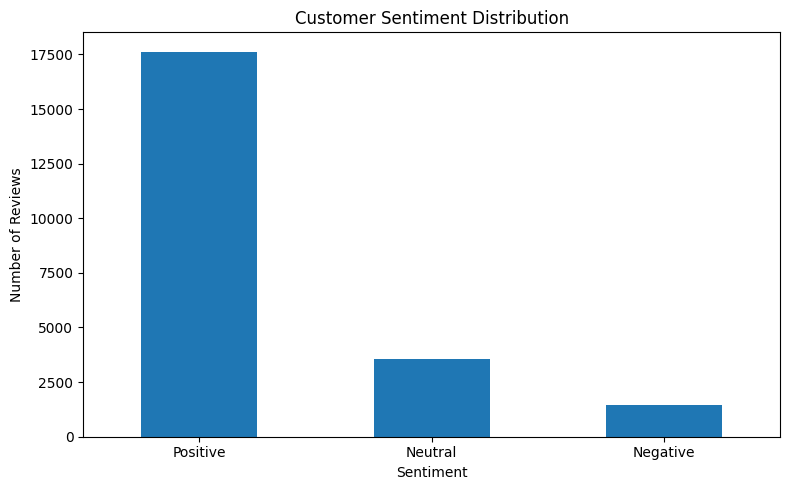

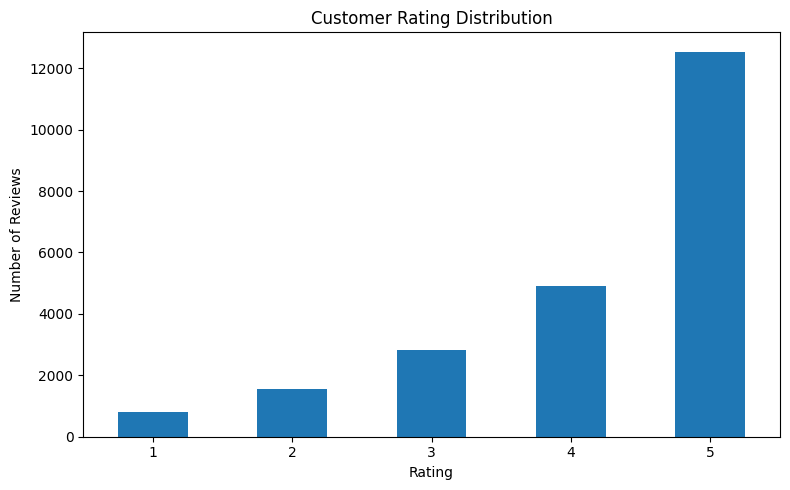

Sentiment vs Rating:


Sentiment,Negative,Neutral,Positive
Rating,,,
1,323,268,230
2,389,529,631
3,429,841,1553
4,198,874,3836
5,116,1045,11379


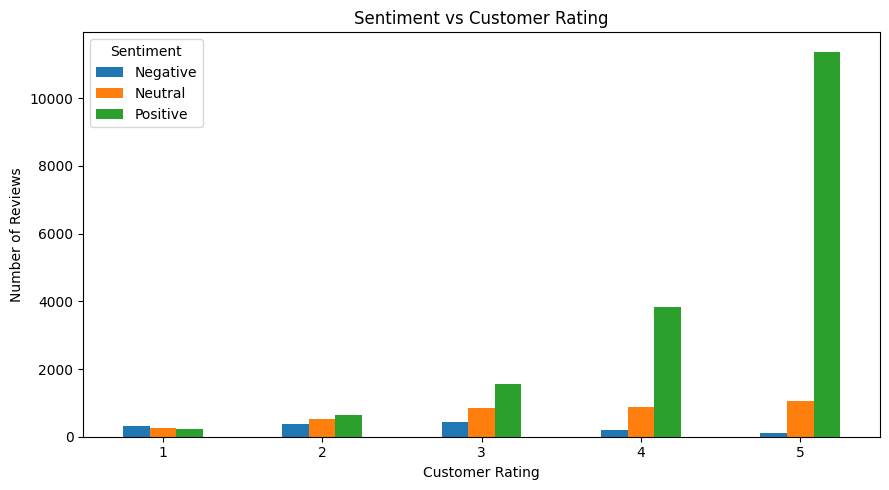

Negative sentiment with high ratings:


,Review Text,Rating,Sentiment
58,"I got this in the petite length, size o, and i...",4,Negative
76,I would have loved this dress if the bust and ...,4,Negative
162,My usual size 6 fits perfectly... yes the meta...,4,Negative
204,I loved this top; it reminded me of one i have...,4,Negative
253,I have this dress on today in white and i am c...,5,Negative
367,Not sure why this shirt is getting bad reviews...,5,Negative
371,I tried this on the other day at the local sto...,5,Negative
618,The fit on these pants is just right for me. i...,5,Negative
648,This swimsuit fits exactly as i had hoped. i p...,5,Negative
674,These fit me really well. i tend to have a pro...,5,Negative


Positive sentiment with low ratings:


,Review Text,Rating,Sentiment
5,"I love tracy reese dresses, but this one is no...",2,Positive
56,I am pregnant and i thought this would be a gr...,2,Positive
71,Why do designers keep making crop tops??!! i c...,2,Positive
184,"Online, this looks like a great sweater. i ord...",2,Positive
185,I was worried about this item when i ordered i...,2,Positive
209,Love the fabric of this shirt even though it w...,1,Positive
237,I have a similar pair of capris from retailer ...,2,Positive
241,I loved this dress from the moment i tried it ...,1,Positive
288,"I wanted to love this sweatshirt, but alas, it...",2,Positive
325,"Like another reviewer mentioned, this shirt is...",2,Positive


Project 1 files saved successfully!
Total analysed reviews: 22641

Final sentiment summary:


,Review_Count,Percentage
Sentiment,,
Positive,17629,77.86
Neutral,3557,15.71
Negative,1455,6.43


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
plt.figure(figsize=(8, 5))

sentiment_counts.plot(kind="bar")

plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

rating_counts = clean_df["Rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

rating_counts.plot(kind="bar")

plt.title("Customer Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

sentiment_rating = pd.crosstab(
    clean_df["Rating"],
    clean_df["Sentiment"]
)

print("Sentiment vs Rating:")
display(sentiment_rating)

sentiment_rating.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Sentiment vs Customer Rating")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

print("Negative sentiment with high ratings:")

display(
    clean_df[
        (clean_df["Sentiment"] == "Negative") &
        (clean_df["Rating"] >= 4)
    ][["Review Text", "Rating", "Sentiment"]].head(10)
)

print("Positive sentiment with low ratings:")

display(
    clean_df[
        (clean_df["Sentiment"] == "Positive") &
        (clean_df["Rating"] <= 2)
    ][["Review Text", "Rating", "Sentiment"]].head(10)
)

clean_df.to_csv(
    "Customer_Feedback_Analysis_Final.csv",
    index=False
)

sentiment_summary.to_csv(
    "Sentiment_Summary.csv"
)

print("Project 1 files saved successfully!")

print("Total analysed reviews:", len(clean_df))

print("\nFinal sentiment summary:")
display(sentiment_summary)

files.download("Customer_Feedback_Analysis_Final.csv")

files.download("Sentiment_Summary.csv")